100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:13<00:00,  7.48it/s]


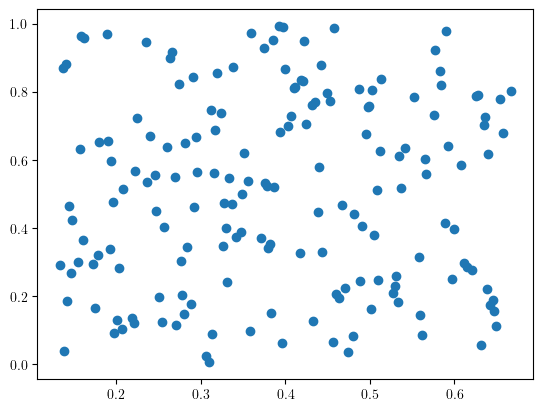

Loaded (241, 2) LF data
Loaded (38, 2) HF data
Loaded (469, 2) LF data
Loaded (81, 2) HF data
Loaded (722, 2) LF data
Loaded (176, 2) HF data
Loaded (1002, 2) LF data
Loaded (271, 2) HF data
Loaded (469, 2) LF data
Loaded (81, 2) HF data
Loaded (722, 2) LF data
Loaded (176, 2) HF data
Loaded (1002, 2) LF data
Loaded (271, 2) HF data

--- Training Initial Model (Iteration 0) ---


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:04<00:00, 20.33it/s]


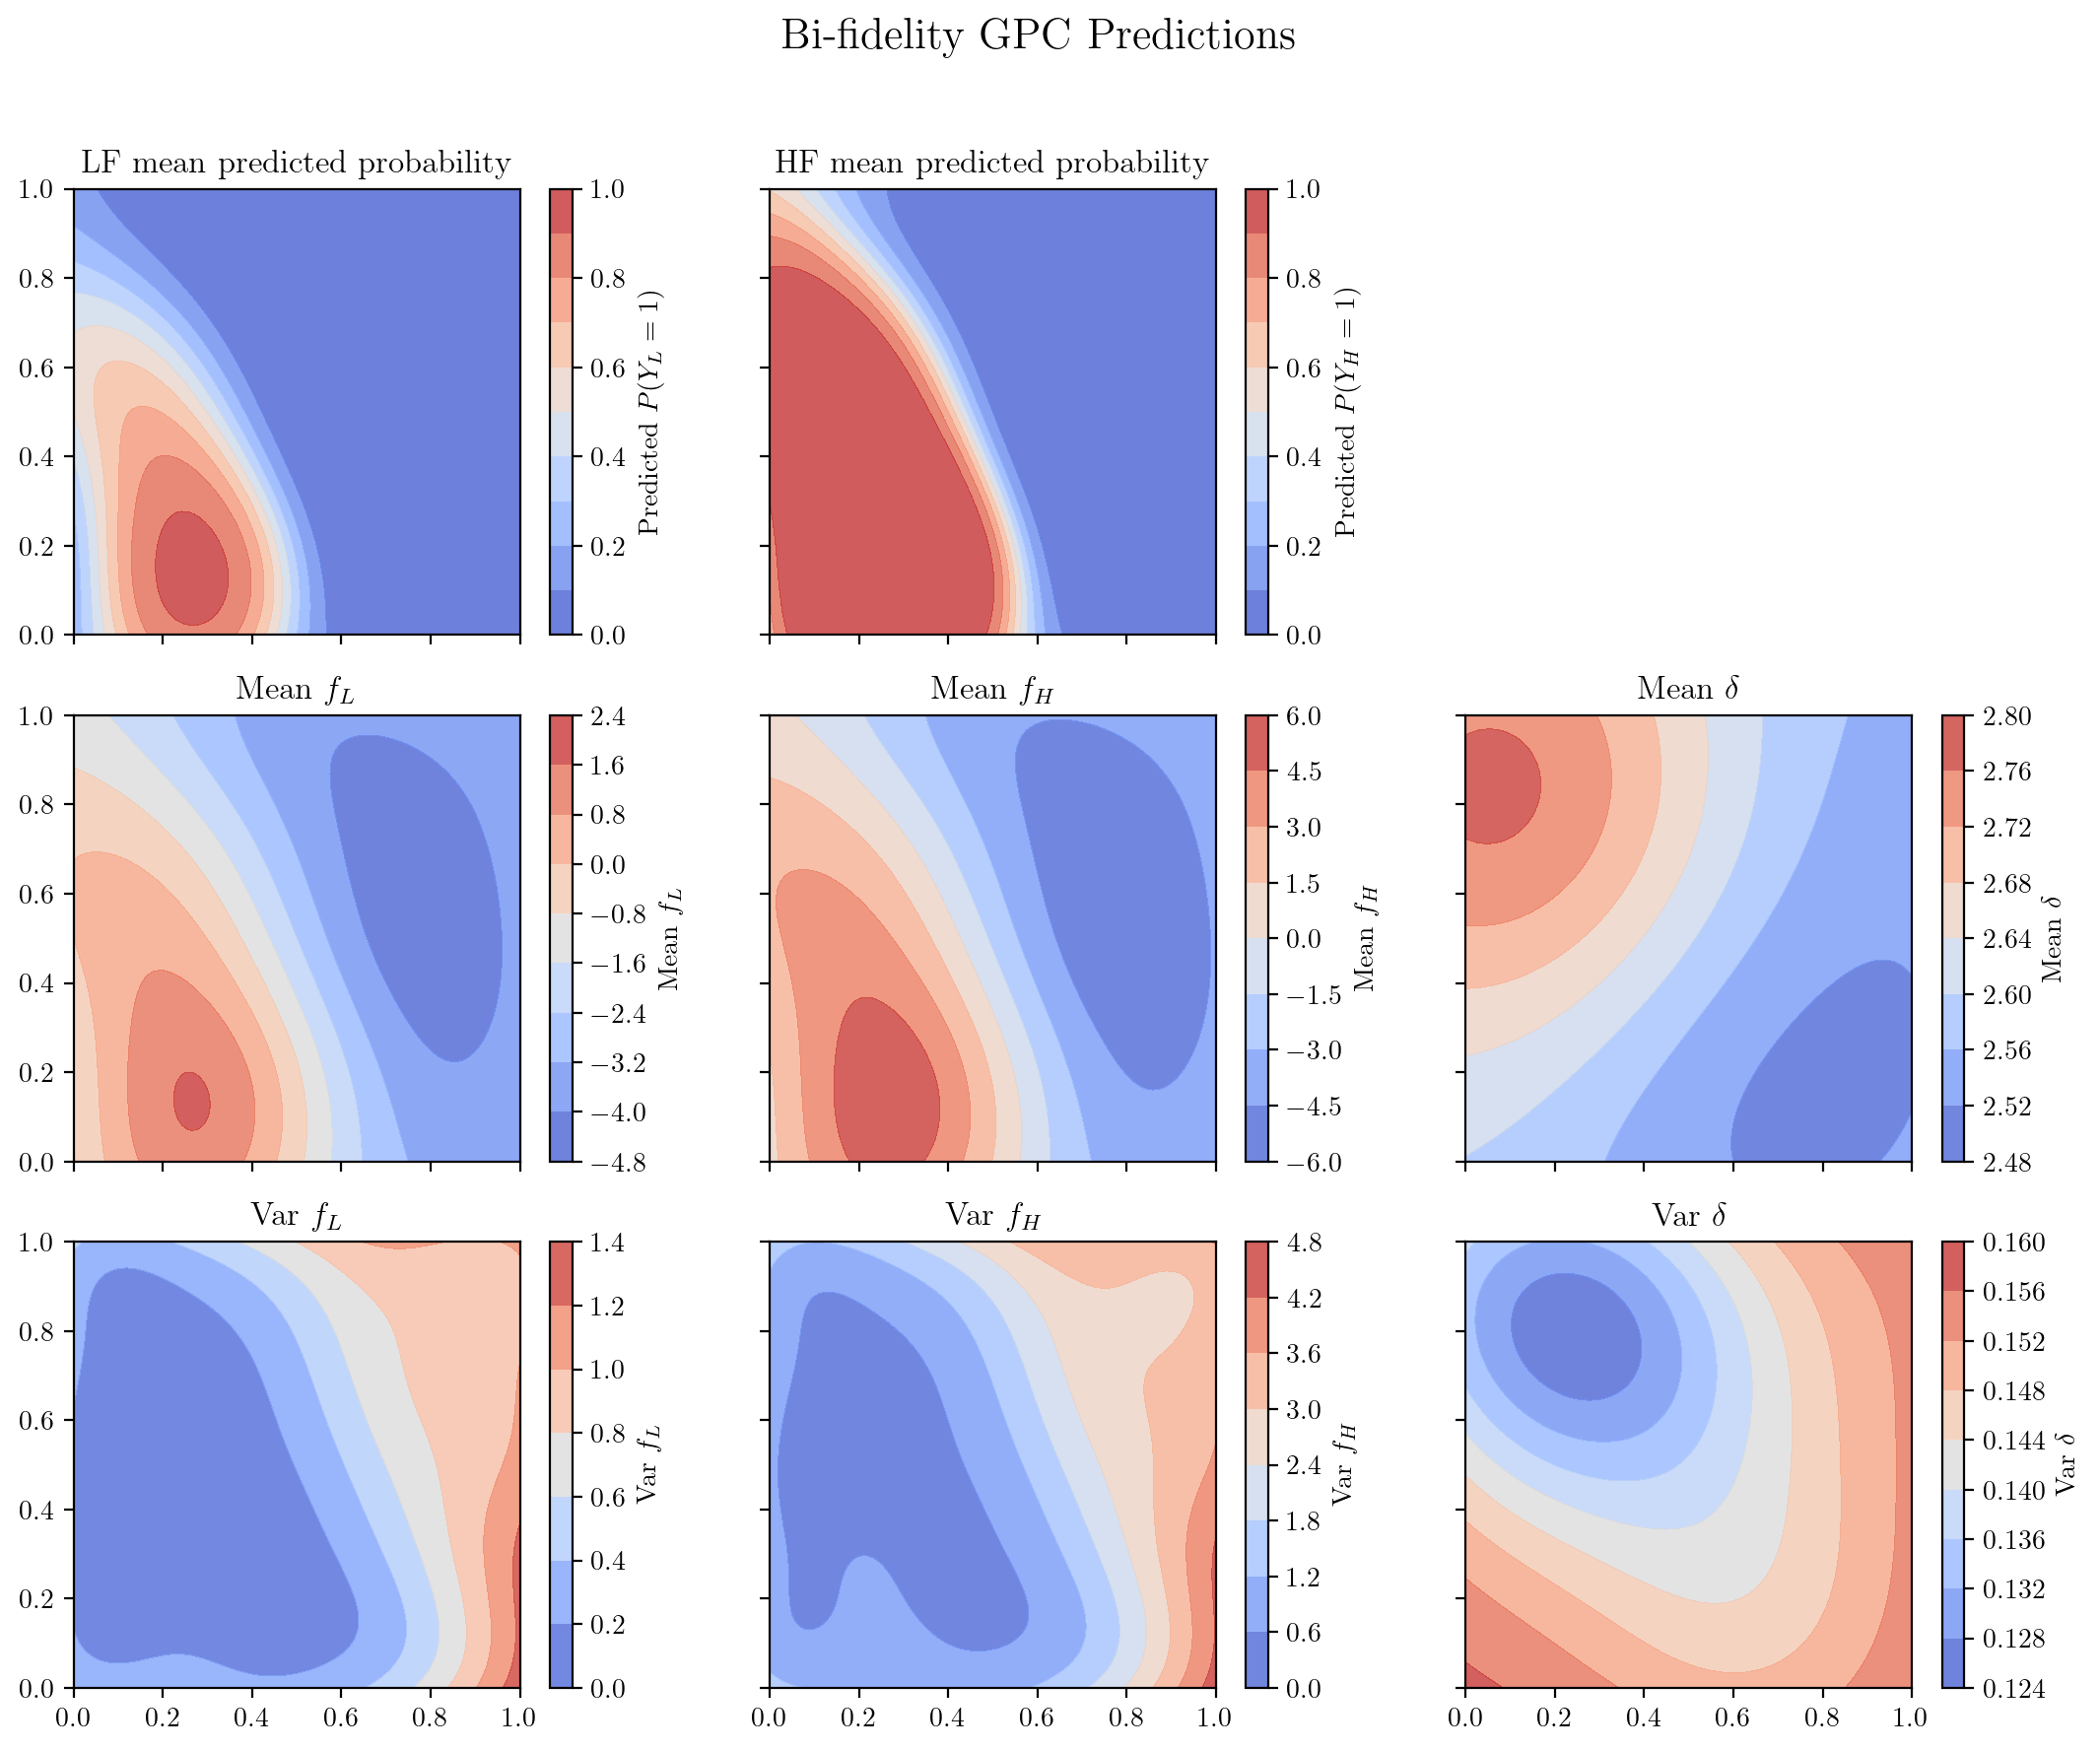

Initial Model ELPP: -0.2035

--- Training BPMI Model (Iteration 1) ---


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:05<00:00, 17.55it/s]


BPMI Model (Iteration 1) ELPP: -0.1216

--- Training BPMI Model (Iteration 2) ---


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:07<00:00, 13.89it/s]


BPMI Model (Iteration 2) ELPP: -0.1311

--- Training BPMI Model (Iteration 3) ---


...

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:06<00:00, 14.69it/s]


Random Model (Iteration 2) ELPP: -0.1166

--- Training Random Sampling Model (Iteration 3) ---


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:07<00:00, 12.59it/s]


Random Model (Iteration 3) ELPP: -0.0998

--- Generating Performance Plot ---


<Figure size 640x480 with 0 Axes>

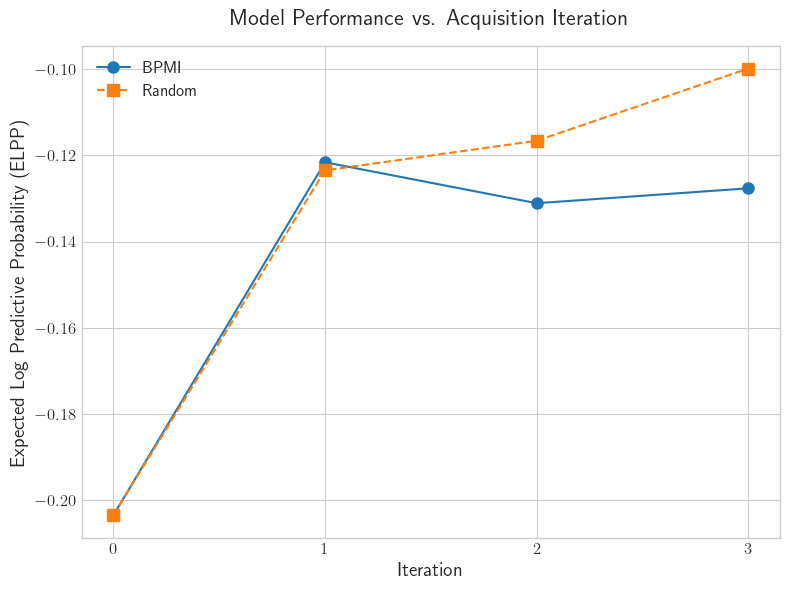

In [1]:
# This generates the PSAAP application figures used in the journal paper

import matplotlib.pyplot as plt
import numpy as np

import sys
# Adjust this path to your specific environment if needed
sys.path.append("/home/murray/Projects/psaap-active-learning")  # For home laptop env

# Assuming src is in the same directory or in the python path
# If not, adjust the path accordingly. For example:
# sys.path.append("../")
from src.problems.psaap_example import load_hf_test_data
from src.models.bfgpc import BFGPC_ELBO
from src.utils_plotting import plot_bfgpc_predictions_two_axes


X_hf_test, Y_hf_test = load_hf_test_data()

plt.scatter(X_hf_test[:, 0], X_hf_test[:, 1])
plt.show()


filepaths_al_lf = ['03_2M.npz', 'AL_01_2M.npz', 'AL_02_2M.npz', 'AL_03_2M.npz']
filepaths_al_hf = ['01_15M.npz', 'AL_01_15M.npz', 'AL_02_15M.npz', 'AL_03_15M.npz']

filepaths_random_lf = ['03_2M.npz', '01_2M.npz', '02_2M.npz']#, '04_2M.npz']
filepaths_random_hf = ['01_15M.npz', '02_15M.npz', '03_15M.npz']#, '04_15M.npz']


def load_lf_data(filepaths, n=None):
    all_xs = []
    all_ys = []
    for filepath in filepaths:
        data = np.load("./../data/" + filepath)
        x = data["xis"][:, [2, 4]].astype(np.float32)
        y = data["chis"]
        all_xs.append(x)
        all_ys.append(y)

    xs = np.concatenate(all_xs, axis=0)
    ys = np.concatenate(all_ys, axis=0)

    if n:
        n = min(n, xs.shape[0])
        xs = xs[:n]
        ys = ys[:n]

    print(f'Loaded {xs.shape} LF data')

    return xs / np.array([[15, 100]]), ys


def load_hf_data(filepaths, n=None):
    all_xs = []
    all_ys = []
    for filepath in filepaths:
        data = np.load("./../data/" + filepath)
        x = data["xis"][:, [2, 4]].astype(np.float32)
        y = data["chis"]
        all_xs.append(x)
        all_ys.append(y)

    xs = np.concatenate(all_xs, axis=0)
    ys = np.concatenate(all_ys, axis=0)

    if n:
        n = min(n, xs.shape[0])
        xs = xs[:n]
        ys = ys[:n]

    print(f'Loaded {xs.shape} HF data')

    return xs / np.array([[15, 100]]), ys


# --- Load all datasets for each iteration ---
X_lf_init, Y_lf_init = load_lf_data(filepaths_al_lf[:1])
X_hf_init, Y_hf_init = load_hf_data(filepaths_al_hf[:1])

X_lf_al1, Y_lf_al1 = load_lf_data(filepaths_al_lf[:2])
X_hf_al1, Y_hf_al1 = load_hf_data(filepaths_al_hf[:2])

X_lf_al2, Y_lf_al2 = load_lf_data(filepaths_al_lf[:3])
X_hf_al2, Y_hf_al2 = load_hf_data(filepaths_al_hf[:3])

X_lf_al3, Y_lf_al3 = load_lf_data(filepaths_al_lf[:4])
X_hf_al3, Y_hf_al3 = load_hf_data(filepaths_al_hf[:4])

X_lf_r1, Y_lf_r1 = load_lf_data(filepaths_random_lf, n=469)
X_hf_r1, Y_hf_r1 = load_hf_data(filepaths_random_hf, n=81)

X_lf_r2, Y_lf_r2 = load_lf_data(filepaths_random_lf, n=722)
X_hf_r2, Y_hf_r2 = load_hf_data(filepaths_random_hf, n=176)

X_lf_r3, Y_lf_r3 = load_lf_data(filepaths_random_lf, n=1002)
X_hf_r3, Y_hf_r3 = load_hf_data(filepaths_random_hf, n=271)

# Group datasets for easier iteration
al_datasets = [
    (X_lf_al1, Y_lf_al1, X_hf_al1, Y_hf_al1),
    (X_lf_al2, Y_lf_al2, X_hf_al2, Y_hf_al2),
    (X_lf_al3, Y_lf_al3, X_hf_al3, Y_hf_al3),
]

random_datasets = [
    (X_lf_r1, Y_lf_r1, X_hf_r1, Y_hf_r1),
    (X_lf_r2, Y_lf_r2, X_hf_r2, Y_hf_r2),
    (X_lf_r3, Y_lf_r3, X_hf_r3, Y_hf_r3),
]


# --- Lists to store performance metrics ---
elpp_al = []
elpp_random = []

# --- Train and Evaluate Initial Model (Iteration 0) ---
print("\n--- Training Initial Model (Iteration 0) ---")
model_init = BFGPC_ELBO(n_inducing_pts=256)
model_init.train_model(X_lf_init, Y_lf_init, X_hf_init, Y_hf_init, n_epochs=100, lr=0.1, verbose=True)
# plot_bfgpc_predictions_two_axes(model_init) # Optional: uncomment to plot predictions
# plt.suptitle("Initial Model (Iteration 0)")

elpp_init = model_init.evaluate_elpp(X_hf_test, Y_hf_test)
print(f"Initial Model ELPP: {elpp_init:.4f}")
elpp_al.append(elpp_init)
elpp_random.append(elpp_init)


# --- Train and Evaluate Active Learning (BPMI) Models ---
for i, (xl, yl, xh, yh) in enumerate(al_datasets):
    #plt.scatter(xh[:, 0], xh[:, 1])
    #plt.show()
    #plt.close()
    
    iteration = i + 1
    print(f"\n--- Training BPMI Model (Iteration {iteration}) ---")
    model = BFGPC_ELBO(n_inducing_pts=256)
    model.train_model(xl, yl, xh, yh, n_epochs=100, lr=0.1, verbose=True)

    #plot_bfgpc_predictions_two_axes(model)
    elpp = model.evaluate_elpp(X_hf_test, Y_hf_test)
    print(f"BPMI Model (Iteration {iteration}) ELPP: {elpp:.4f}")
    elpp_al.append(elpp)


# --- Train and Evaluate Random Sampling Models ---
for i, (xl, yl, xh, yh) in enumerate(random_datasets):
    #plt.scatter(xh[:, 0], xh[:, 1])
    #plt.show()
    #plt.close()
    
    iteration = i + 1
    print(f"\n--- Training Random Sampling Model (Iteration {iteration}) ---")
    model = BFGPC_ELBO(n_inducing_pts=256)
    model.train_model(xl, yl, xh, yh, n_epochs=100, lr=0.1, verbose=True)

    #plot_bfgpc_predictions_two_axes(model)
    elpp = model.evaluate_elpp(X_hf_test, Y_hf_test)
    print(f"Random Model (Iteration {iteration}) ELPP: {elpp:.4f}")
    elpp_random.append(elpp)


# --- Create Publication Quality Plot ---
print("\n--- Generating Performance Plot ---")
iterations = np.arange(4) # Corresponds to 0, 1, 2, 3

# Use a professional plot style
plt.style.use('seaborn-v0_8-whitegrid')

fig, ax = plt.subplots(figsize=(8, 6))

# Plot BPMI (Active Learning) results
ax.plot(iterations, elpp_al, marker='o', linestyle='-', markersize=8, label='BPMI')

# Plot Random Sampling results
ax.plot(iterations, elpp_random, marker='s', linestyle='--', markersize=8, label='Random')

# Set labels, title, and legend
ax.set_xlabel('Iteration', fontsize=14)
ax.set_ylabel('Expected Log Predictive Probability (ELPP)', fontsize=14)
ax.set_title('Model Performance vs. Acquisition Iteration', fontsize=16, pad=15)
ax.legend(fontsize=12)

# Customize ticks
ax.set_xticks(iterations)
ax.tick_params(axis='both', which='major', labelsize=12)

# Ensure layout is tight
plt.tight_layout()

# Show the final plot
plt.show()

In [6]:
filepaths_random_hf = ['01_15M.npz', '02_15M.npz', '03_15M.npz', '04_15M.npz']

for fp in filepaths_random_hf:
    data = np.load("./../data/" + fp)
    x = data["xis"][:, [2, 4]].astype(np.float32)
    print(x.shape)
    


(38, 2)
(137, 2)
(254, 2)
(171, 2)


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:13<00:00,  7.51it/s]


Loaded (241, 2) LF data
Loaded (38, 2) HF data
Loaded (469, 2) LF data
Loaded (81, 2) HF data
Loaded (722, 2) LF data
Loaded (176, 2) HF data
Loaded (1002, 2) LF data
Loaded (271, 2) HF data
Loaded (469, 2) LF data
Loaded (81, 2) HF data
Loaded (722, 2) LF data
Loaded (176, 2) HF data
Loaded (788, 2) LF data
Loaded (271, 2) HF data

--- Training Initial Model (Iteration 0) ---


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:04<00:00, 20.79it/s]


Initial Model ELPP: -0.2718

--- Training BPMI Model (Iteration 1) (len(yh) = 81) ---


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:06<00:00, 31.90it/s]


...

Random Model (Iteration 1) ELPP: -0.2439

--- Training Random Sampling Model (Iteration 2) (len(yh) = 176) ---


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:10<00:00, 19.86it/s]


Random Model (Iteration 2) ELPP: -0.2527

--- Training Random Sampling Model (Iteration 3) (len(yh) = 271) ---


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:14<00:00, 13.78it/s]


Random Model (Iteration 3) ELPP: -0.2085

--- Generating Performance Plot ---


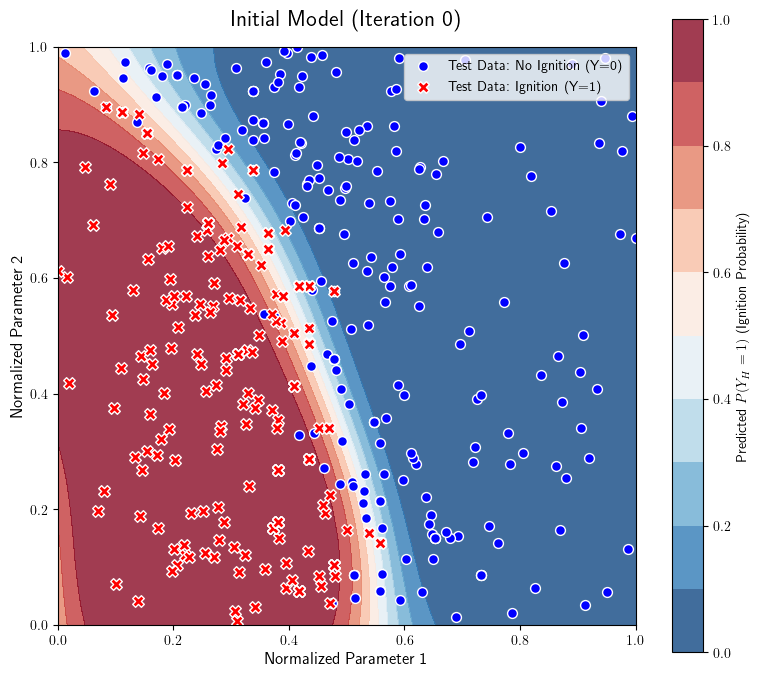

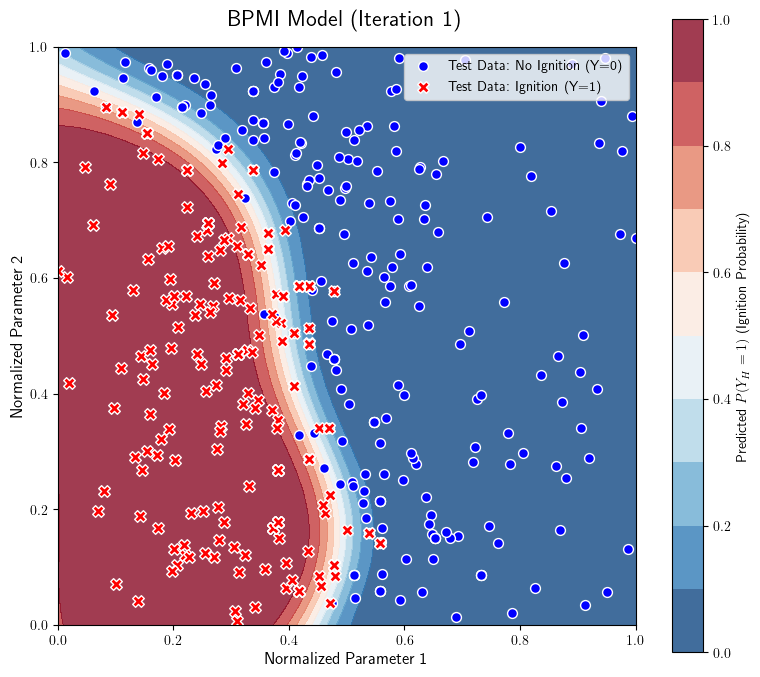

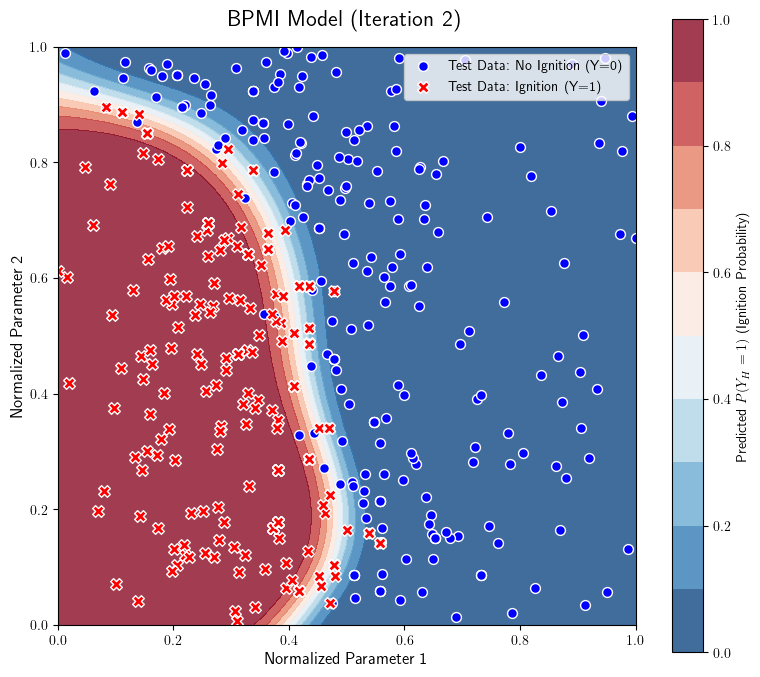

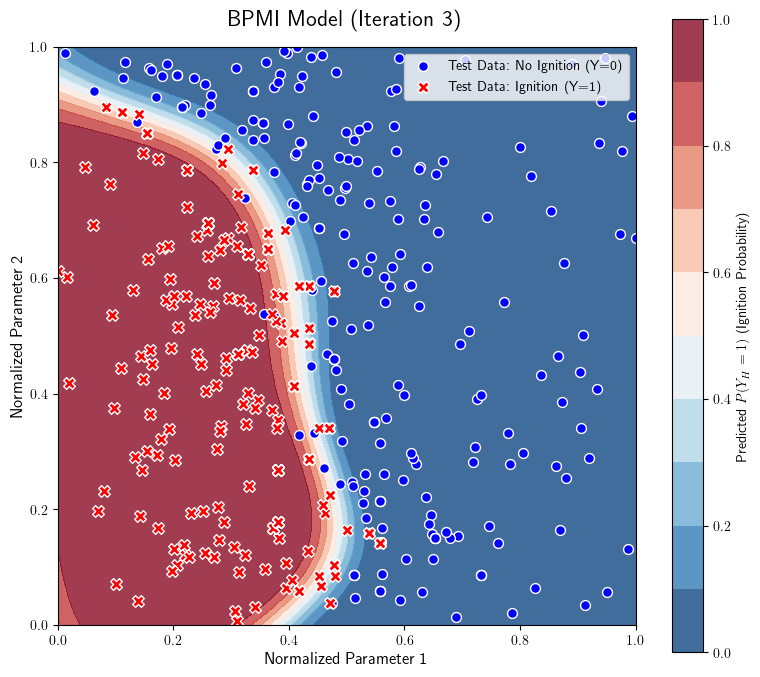

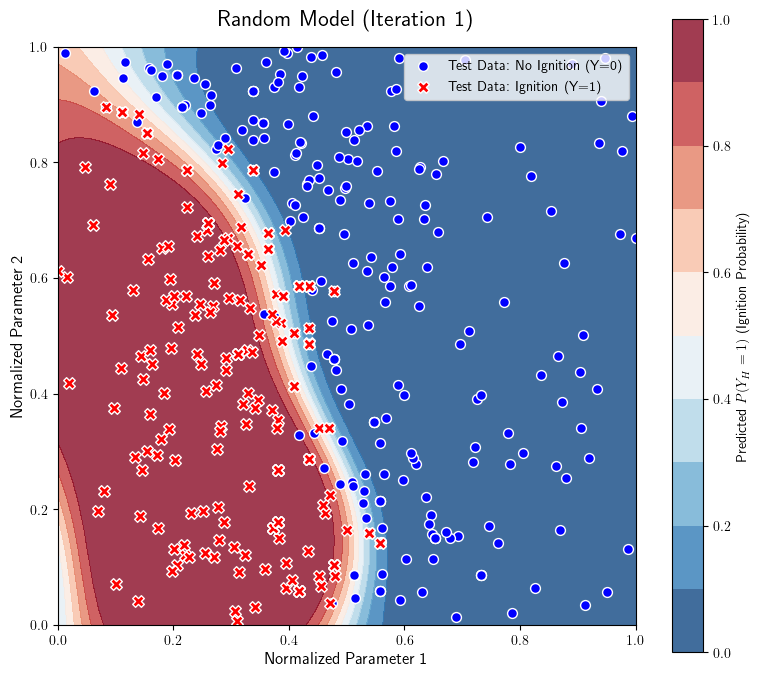

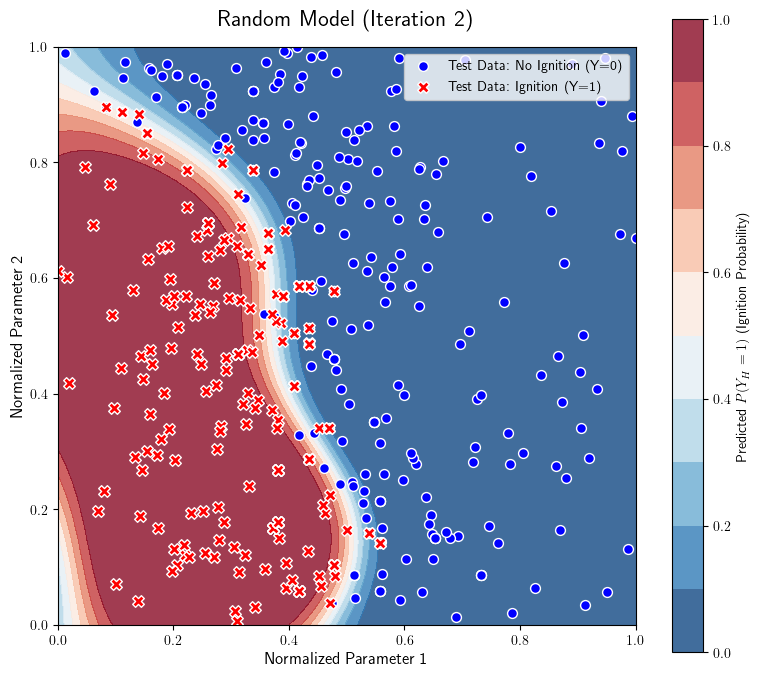

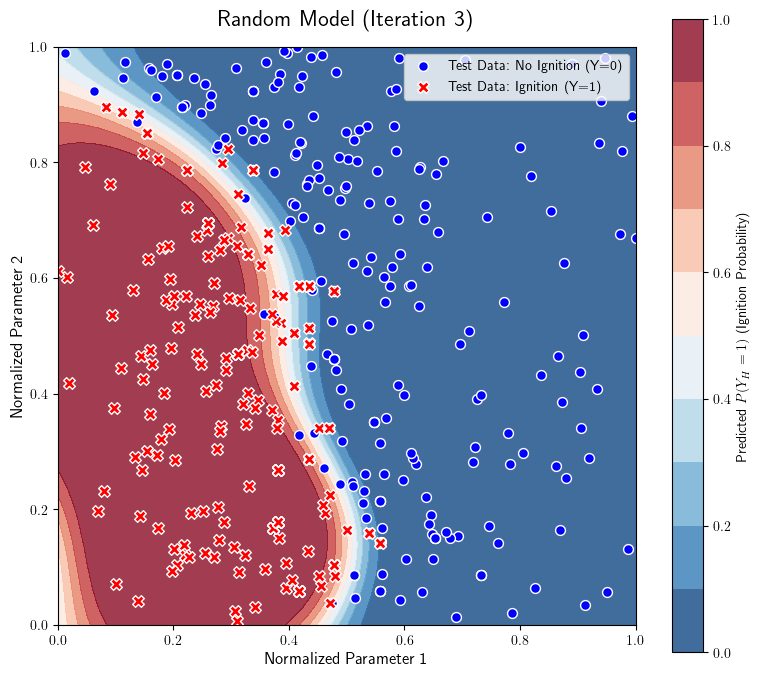

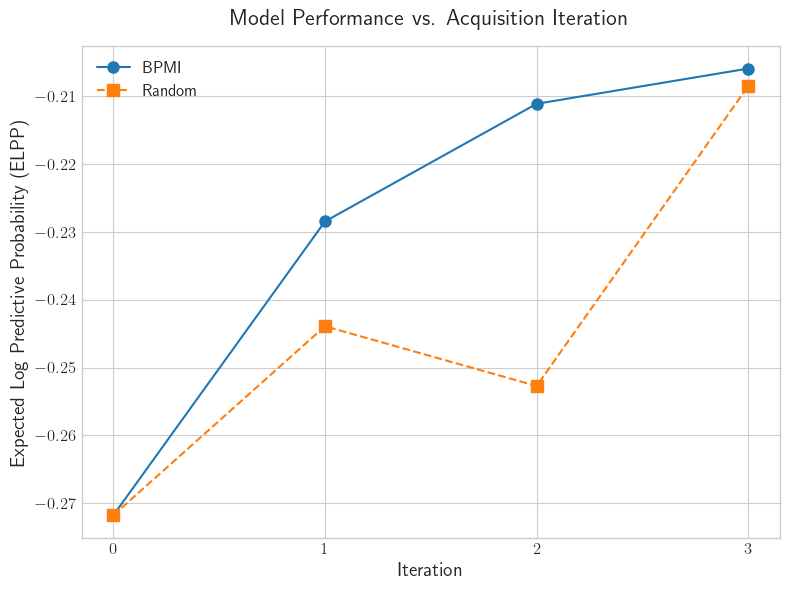

In [1]:
# This generates the PSAAP application figures used in the journal paper

import matplotlib.pyplot as plt
import numpy as np
import torch
import gpytorch

np.random.seed(42)

import sys
# Adjust this path to your specific environment if needed
sys.path.append("/home/murray/Projects/psaap-active-learning")

# Use your actual data loading functions from your project structure
from src.problems.psaap_example import load_hf_test_data
from src.models.bfgpc import BFGPC_ELBO
# The original plot_bfgpc_predictions_two_axes is no longer needed for this specific task
# from src.utils_plotting import plot_bfgpc_predictions_two_axes


X_hf_test, Y_hf_test = load_hf_test_data()

# Filepaths for loading iterative data
filepaths_al_lf = ['03_2M.npz', 'AL_01_2M.npz', 'AL_02_2M.npz', 'AL_03_2M.npz']
filepaths_al_hf = ['01_15M.npz', 'AL_01_15M.npz', 'AL_02_15M.npz', 'AL_03_15M.npz']

# Note: You had commented out the last file for random. I've kept it that way.
filepaths_random_lf = ['03_2M.npz', '01_2M.npz'] #, '02_2M.npz']#, '04_2M.npz']
filepaths_random_hf = ['01_15M.npz', '03_15M.npz']#, '02_15M.npz', '04_15M.npz']  # Use 2 and 4 for an augmented test set


def load_lf_data(filepaths, n=None):
    all_xs = []
    all_ys = []
    for filepath in filepaths:
        data = np.load("./../data/" + filepath)
        x = data["xis"][:, [2, 4]].astype(np.float32)
        y = data["chis"]
        all_xs.append(x)
        all_ys.append(y)

    xs = np.concatenate(all_xs, axis=0)
    ys = np.concatenate(all_ys, axis=0)

    if n:
        n = min(n, xs.shape[0])
        xs = xs[:n]
        ys = ys[:n]

    print(f'Loaded {xs.shape} LF data')
    return xs / np.array([[15, 100]]), ys


def load_hf_data(filepaths, n=None):
    all_xs = []
    all_ys = []
    for filepath in filepaths:
        data = np.load("./../data/" + filepath)
        x = data["xis"][:, [2, 4]].astype(np.float32)
        y = data["chis"]
        all_xs.append(x)
        all_ys.append(y)

    xs = np.concatenate(all_xs, axis=0)
    ys = np.concatenate(all_ys, axis=0)

    if n:
        n = min(n, xs.shape[0])
        xs = xs[:n]
        ys = ys[:n]

    print(f'Loaded {xs.shape} HF data')
    return xs / np.array([[15, 100]]), ys


# --- New Plotting Function ---
def plot_hf_predictions_with_test_data(model, X_test, Y_test, title, grid_res=100):
    """
    Plots the predicted P(Y_H=1) surface and overlays test data points.
    """
    model.eval()

    # Create a grid to evaluate the model on
    xi = np.linspace(0, 1, grid_res)
    yi = np.linspace(0, 1, grid_res)
    xx, yy = np.meshgrid(xi, yi)
    grid_points_np = np.vstack([xx.ravel(), yy.ravel()]).T
    grid_points_torch = torch.tensor(grid_points_np, dtype=torch.float32)

    # Get model predictions on the grid
    with torch.no_grad(), gpytorch.settings.fast_pred_var():
        # The forward call of BFGPC_ELBO returns the HF predicted probability
        predicted_probs_hf_grid = model(grid_points_torch)

    predicted_probs_hf_grid_reshaped = predicted_probs_hf_grid.numpy().reshape(grid_res, grid_res)

    # Create the plot
    fig, ax = plt.subplots(figsize=(8, 7))

    # Plot the predicted probability surface
    contour = ax.contourf(xx, yy, predicted_probs_hf_grid_reshaped,
                          levels=np.linspace(0, 1, 11), cmap='RdBu_r', alpha=0.8)
    fig.colorbar(contour, ax=ax, label='Predicted $P(Y_H=1)$ (Ignition Probability)')

    # Overlay test data, colored by true outcome
    # Separate ignition (Y=1) and no-ignition (Y=0) points for clarity
    ign_points = X_test[Y_test.ravel() == 1]
    no_ign_points = X_test[Y_test.ravel() == 0]

    ax.scatter(no_ign_points[:, 0], no_ign_points[:, 1], c='blue', marker='o',
               edgecolors='white', s=50, label='Test Data: No Ignition (Y=0)')
    ax.scatter(ign_points[:, 0], ign_points[:, 1], c='red', marker='X',
               edgecolors='white', s=70, label='Test Data: Ignition (Y=1)')

    # Formatting
    ax.set_xlabel('Normalized Parameter 1', fontsize=12)
    ax.set_ylabel('Normalized Parameter 2', fontsize=12)
    ax.set_title(title, fontsize=16, pad=15)
    ax.legend(loc='best')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal', adjustable='box')
    plt.tight_layout()


# --- Load all datasets for each iteration ---
X_lf_init, Y_lf_init = load_lf_data(filepaths_al_lf[:1])
X_hf_init, Y_hf_init = load_hf_data(filepaths_al_hf[:1])

al_datasets = [
    (load_lf_data(filepaths_al_lf[:2]), load_hf_data(filepaths_al_hf[:2])),
    (load_lf_data(filepaths_al_lf[:3]), load_hf_data(filepaths_al_hf[:3])),
    (load_lf_data(filepaths_al_lf[:4]), load_hf_data(filepaths_al_hf[:4])),
]

random_datasets = [
    (load_lf_data(filepaths_random_lf, n=469), load_hf_data(filepaths_random_hf, n=81)), # These file lists are different now
    (load_lf_data(filepaths_random_lf, n=722), load_hf_data(filepaths_random_hf, n=176)),
    (load_lf_data(filepaths_random_lf, n=1002), load_hf_data(filepaths_random_hf, n=271)),
]

# --- Lists to store performance metrics ---
elpp_al = []
elpp_random = []

# --- Train and Evaluate Initial Model (Iteration 0) ---
print("\n--- Training Initial Model (Iteration 0) ---")
model_init = BFGPC_ELBO(n_inducing_pts=256)
model_init.train_model(X_lf_init, Y_lf_init, X_hf_init, Y_hf_init, n_epochs=200, lr=0.1, verbose=True, n_inits=1)
elpp_init = model_init.evaluate_elpp(X_hf_test, Y_hf_test)
print(f"Initial Model ELPP: {elpp_init:.4f}")
elpp_al.append(elpp_init)
elpp_random.append(elpp_init)
# Generate the new diagnostic plot for the initial model
plot_hf_predictions_with_test_data(model_init, X_hf_test, Y_hf_test, "Initial Model (Iteration 0)")

# --- Train and Evaluate Active Learning (BPMI) Models ---
for i, ((xl, yl), (xh, yh)) in enumerate(al_datasets):
    iteration = i + 1
    print(f"\n--- Training BPMI Model (Iteration {iteration}) (len(yh) = {len(yh)}) ---")
    model = BFGPC_ELBO(n_inducing_pts=len(yh))
    model.train_model(xl, yl, xh, yh, n_epochs=200, lr=0.1, verbose=True, n_inits=1)
    elpp = model.evaluate_elpp(X_hf_test, Y_hf_test)
    print(f"BPMI Model (Iteration {iteration}) ELPP: {elpp:.4f}")
    elpp_al.append(elpp)
    # Generate diagnostic plot for this iteration
    plot_hf_predictions_with_test_data(model, X_hf_test, Y_hf_test, f"BPMI Model (Iteration {iteration})")

# --- Train and Evaluate Random Sampling Models ---
for i, ((xl, yl), (xh, yh)) in enumerate(random_datasets):
    iteration = i + 1
    print(f"\n--- Training Random Sampling Model (Iteration {iteration}) (len(yh) = {len(yh)}) ---")
    model = BFGPC_ELBO(n_inducing_pts=len(yh))
    model.train_model(xl, yl, xh, yh, n_epochs=200, lr=0.1, verbose=True, n_inits=1)
    elpp = model.evaluate_elpp(X_hf_test, Y_hf_test)
    print(f"Random Model (Iteration {iteration}) ELPP: {elpp:.4f}")
    elpp_random.append(elpp)
    # Generate diagnostic plot for this iteration
    plot_hf_predictions_with_test_data(model, X_hf_test, Y_hf_test, f"Random Model (Iteration {iteration})")


# --- Save ELPP Results to File ---
print("\n--- Saving final ELPP results ---")
iterations = np.arange(len(elpp_al))
results_filename = 'psaap_elpp_results.npz'

# Convert lists to numpy arrays for saving
elpp_al_np = np.array(elpp_al)
elpp_random_np = np.array(elpp_random)

#np.savez_compressed(
#    results_filename,
#    iterations=iterations,
#    bpmi_elpp=elpp_al_np,
#    random_elpp=elpp_random_np
#)
#print(f"Results saved to {results_filename}")

import matplotlib
matplotlib.rcdefaults()
matplotlib.rcParams['text.usetex'] = True

iterations = np.arange(len(elpp_al))

fig, ax = plt.subplots(figsize=(5, 3), dpi=200)
ax.plot(iterations, elpp_al, marker='o', linestyle='-', markersize=8, label='$\\mathrm{BPMI}$')
ax.plot(iterations, elpp_random, marker='s', linestyle='--', markersize=8, label='$\\mathrm{Random}$', color='C3')
ax.set_xlabel('$\\mathrm{Iteration}$')
ax.set_ylabel('$\\mathrm{ELPP}$')
ax.legend(fontsize=12)
ax.set_xticks(iterations)
ax.tick_params(axis='both', which='major')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

# Show all generated plots at the end
plt.savefig('psaap-elpp.pdf')
plt.show()



--- Saving final ELPP results ---
Results saved to psaap_elpp_results.npz


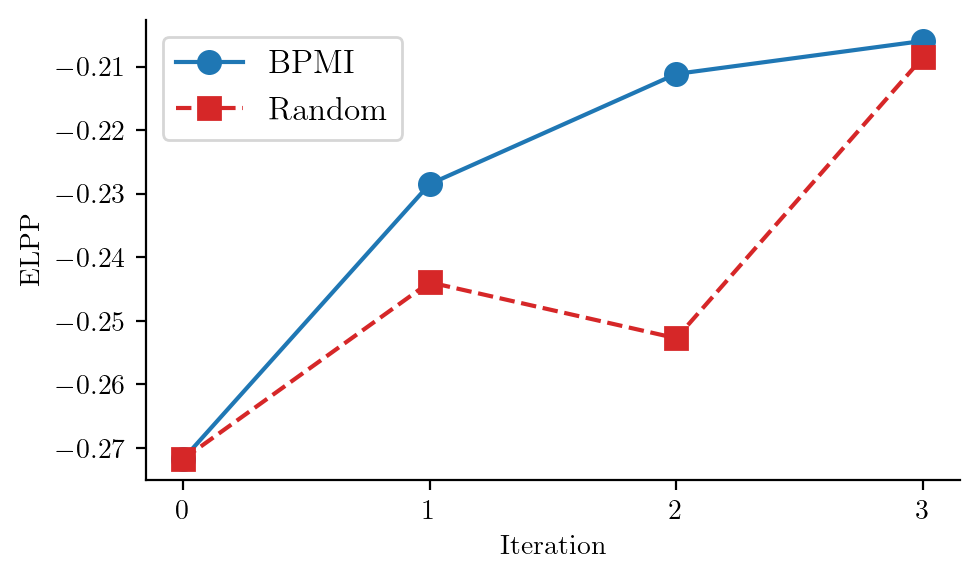

In [20]:
# Publication quality plot of ELPP results

# --- Save ELPP Results to File ---
print("\n--- Saving final ELPP results ---")
iterations = np.arange(len(elpp_al))
results_filename = 'psaap_elpp_results.npz'

# Convert lists to numpy arrays for saving
elpp_al_np = np.array(elpp_al)
elpp_random_np = np.array(elpp_random)

np.savez_compressed(
    results_filename,
    iterations=iterations,
    bpmi_elpp=elpp_al_np,
    random_elpp=elpp_random_np
)
print(f"Results saved to {results_filename}")

import matplotlib
matplotlib.rcdefaults()

matplotlib.rcParams['text.usetex'] = True

iterations = np.arange(len(elpp_al))

fig, ax = plt.subplots(figsize=(5, 3), dpi=200)
ax.plot(iterations, elpp_al, marker='o', linestyle='-', markersize=8, label='$\\mathrm{BPMI}$')
ax.plot(iterations, elpp_random, marker='s', linestyle='--', markersize=8, label='$\\mathrm{Random}$', color='C3')
ax.set_xlabel('$\\mathrm{Iteration}$')
ax.set_ylabel('$\\mathrm{ELPP}$')
ax.legend(fontsize=12)
ax.set_xticks(iterations)
ax.tick_params(axis='both', which='major')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

# Show all generated plots at the end
plt.savefig('psaap-elpp.pdf')
plt.show()


--- Training Initial Model (Iteration 0) ---


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:12<00:00, 15.84it/s]


Initial Model ELPP: -0.2750

--- Training BPMI Model (Iteration 1) (len(yh) = 81) ---


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:06<00:00, 30.87it/s]


BPMI Model (Iteration 1) ELPP: -0.2223

--- Training BPMI Model (Iteration 2) (len(yh) = 176) ---


...

Random Model (Iteration 1) ELPP: -0.2288

--- Training Random Sampling Model (Iteration 2) (len(yh) = 176) ---


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:09<00:00, 21.87it/s]


Random Model (Iteration 2) ELPP: -0.2476

--- Training Random Sampling Model (Iteration 3) (len(yh) = 271) ---


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:13<00:00, 14.36it/s]


Random Model (Iteration 3) ELPP: -0.2113

--- Generating final summary plots ---

--- Saving final ELPP results ---
Results saved to psaap_elpp_results_2.npz


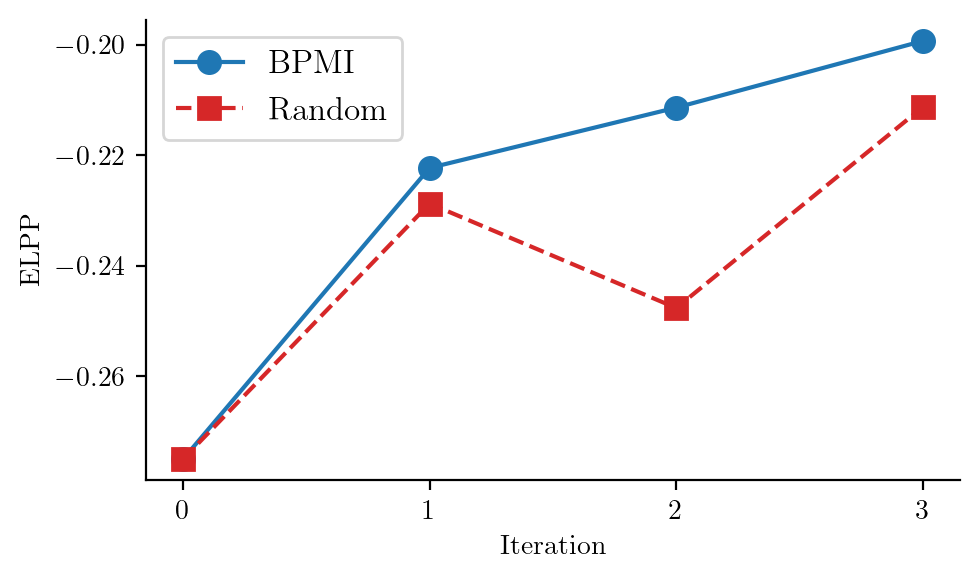

In [40]:






# --- Lists to store performance metrics ---
elpp_al = []
elpp_random = []
final_al_model, final_random_model = None, None

# --- Train and Evaluate Initial Model (Iteration 0) ---
print("\n--- Training Initial Model (Iteration 0) ---")
model_init = BFGPC_ELBO(n_inducing_pts=256)
model_init.train_model(X_lf_init, Y_lf_init, X_hf_init, Y_hf_init, n_epochs=200, lr=0.1, verbose=True, n_inits=1)
elpp_init = model_init.evaluate_elpp(X_hf_test, Y_hf_test)
print(f"Initial Model ELPP: {elpp_init:.4f}")
elpp_al.append(elpp_init)
elpp_random.append(elpp_init)

# --- Train and Evaluate Active Learning (BPMI) Models ---
for i, ((xl, yl), (xh, yh)) in enumerate(al_datasets):
    iteration = i + 1
    print(f"\n--- Training BPMI Model (Iteration {iteration}) (len(yh) = {len(yh)}) ---")
    model = BFGPC_ELBO(n_inducing_pts=len(yh))
    model.train_model(xl, yl, xh, yh, n_epochs=200, lr=0.1, verbose=True, n_inits=1)
    elpp = model.evaluate_elpp(X_hf_test, Y_hf_test)
    print(f"BPMI Model (Iteration {iteration}) ELPP: {elpp:.4f}")
    elpp_al.append(elpp)
    final_al_model = model # Store the final model

# --- Train and Evaluate Random Sampling Models ---
for i, ((xl, yl), (xh, yh)) in enumerate(random_datasets):
    iteration = i + 1
    print(f"\n--- Training Random Sampling Model (Iteration {iteration}) (len(yh) = {len(yh)}) ---")
    model = BFGPC_ELBO(n_inducing_pts=len(yh))
    model.train_model(xl, yl, xh, yh, n_epochs=200, lr=0.1, verbose=True, n_inits=1)
    elpp = model.evaluate_elpp(X_hf_test, Y_hf_test)
    print(f"Random Model (Iteration {iteration}) ELPP: {elpp:.4f}")
    elpp_random.append(elpp)
    final_random_model = model # Store the final model


# --- Generate Final Model and Data Visualization Plots ---
print("\n--- Generating final summary plots ---")
# Create data history lists
al_lf_history = [(X_lf_init, Y_lf_init)] + [d[0] for d in al_datasets]
al_hf_history = [(X_hf_init, Y_hf_init)] + [d[1] for d in al_datasets]
random_lf_history = [(X_lf_init, Y_lf_init)] + [d[0] for d in random_datasets]
random_hf_history = [(X_hf_init, Y_hf_init)] + [d[1] for d in random_datasets]



# --- Save ELPP Results to File ---
print("\n--- Saving final ELPP results ---")
iterations = np.arange(len(elpp_al))
results_filename = 'psaap_elpp_results_2.npz'
np.savez_compressed(results_filename, iterations=iterations, bpmi_elpp=np.array(elpp_al), random_elpp=np.array(elpp_random))
print(f"Results saved to {results_filename}")


# --- Create Final ELPP Comparison Plot ---
import matplotlib
matplotlib.rcdefaults()
matplotlib.rcParams['text.usetex'] = True

fig, ax = plt.subplots(figsize=(5, 3), dpi=200)
ax.plot(iterations, elpp_al, marker='o', linestyle='-', markersize=8, label='$\\mathrm{BPMI}$')
ax.plot(iterations, elpp_random, marker='s', linestyle='--', markersize=8, label='$\\mathrm{Random}$', color='C3')
ax.set_xlabel('$\\mathrm{Iteration}$')
ax.set_ylabel('$\\mathrm{ELPP}$')
ax.legend(fontsize=12)
ax.set_xticks(iterations)
ax.tick_params(axis='both', which='major')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('psaap-elpp.pdf')

# Show all generated plots at the end
plt.show()

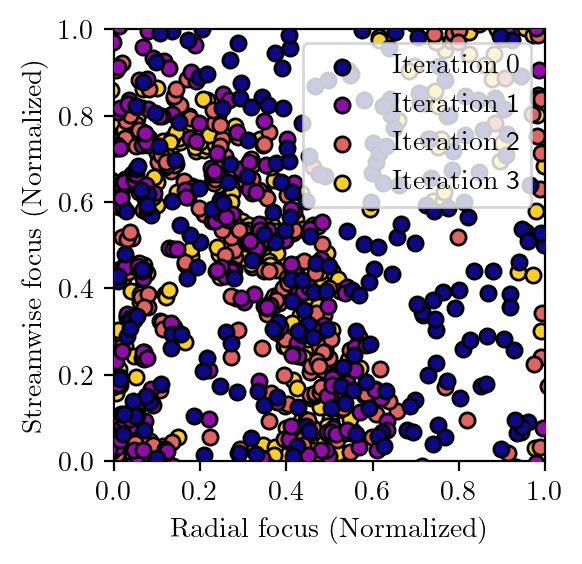

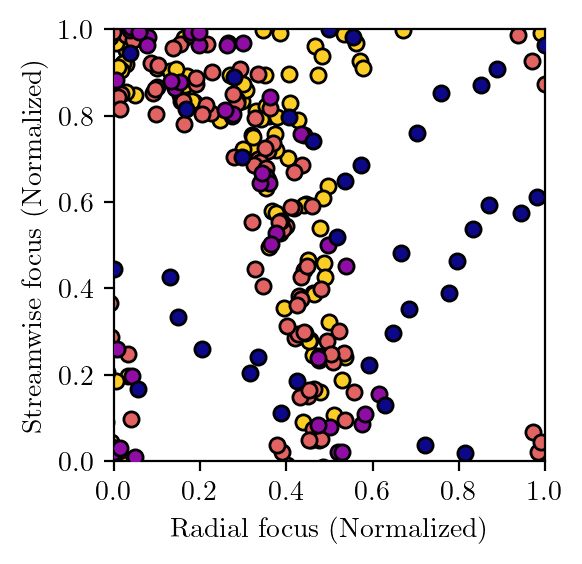

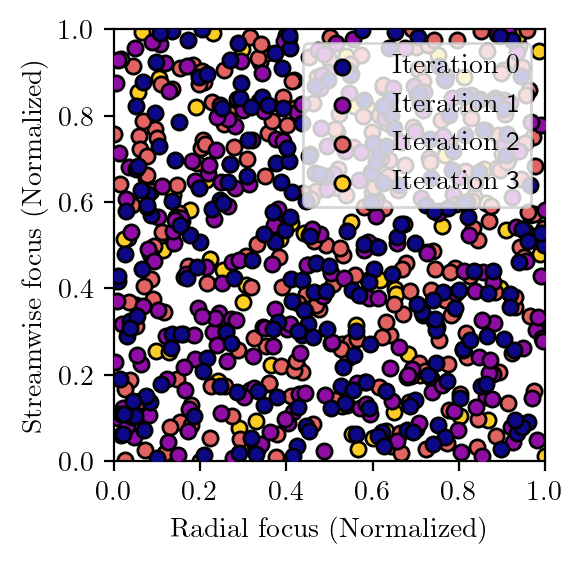

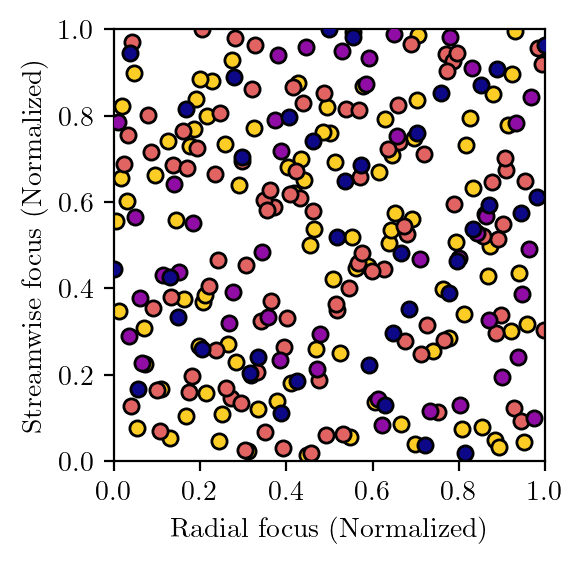

In [41]:

# --- New Plotting Function 1: Iterative Data ---
def plot_iterative_data(cumulative_datasets, title, legend=True):
    """
    Plots training data points, colored by the iteration they were acquired.
    'cumulative_datasets' is a list of (X, Y) tuples, one for each iteration.
    """
    fig, ax = plt.subplots(figsize=(3, 3), dpi=200)
    # Define a color scheme for the iterations
    colors = plt.cm.plasma(np.linspace(0, 0.9, len(cumulative_datasets)))

    # Plot initial data (Iteration 0)
    X_prev, _ = cumulative_datasets[0]
    ax.scatter(X_prev[:, 0], X_prev[:, 1], color=colors[0],
               edgecolors='black', s=30, label='$\\textrm{Iteration 0}$', zorder=len(cumulative_datasets)+1)

    # Plot newly added data for each subsequent iteration
    for i in range(1, len(cumulative_datasets)):
        X_curr, _ = cumulative_datasets[i]
        # Find points in the current set that were not in the previous set
        X_new = X_curr[len(X_prev):]
        # Plot with decreasing zorder so earlier points can be seen if overlapped
        ax.scatter(X_new[:, 0], X_new[:, 1], color=colors[i],
                   edgecolors='black', s=30, label='$\\textrm{Iteration }$' + f'{i}', zorder=len(cumulative_datasets)-i)
        X_prev = X_curr  # Update for the next loop

    ax.set_xlabel('$\\textrm{Radial focus (Normalized)}$')
    ax.set_ylabel('$\\textrm{Streamwise focus (Normalized)}$')
    #ax.set_title(title, fontsize=16, pad=15)
    if legend:
        ax.legend(loc='upper right')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal', adjustable='box')
    plt.tight_layout()

    plt.savefig(title + '.pdf')
    plt.show()



plot_iterative_data(al_lf_history, 'BPMI - Low-Fidelity Training Data by Iteration')
plot_iterative_data(al_hf_history, 'BPMI - High-Fidelity Training Data by Iteration', legend=False)
plot_iterative_data(random_lf_history, 'Random - Low-Fidelity Training Data by Iteration')
plot_iterative_data(random_hf_history, 'Random - High-Fidelity Training Data by Iteration', legend=False)

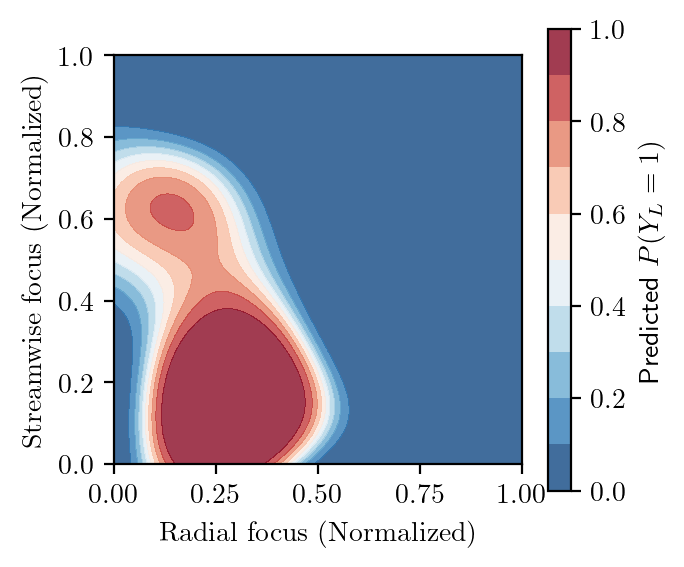

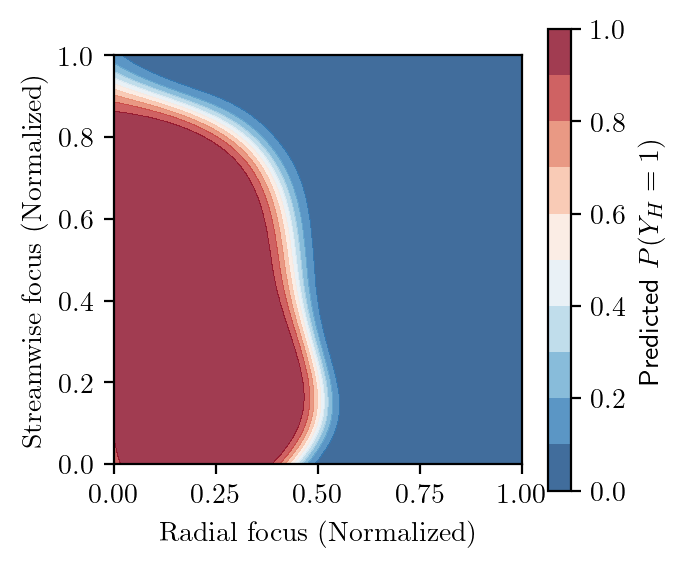

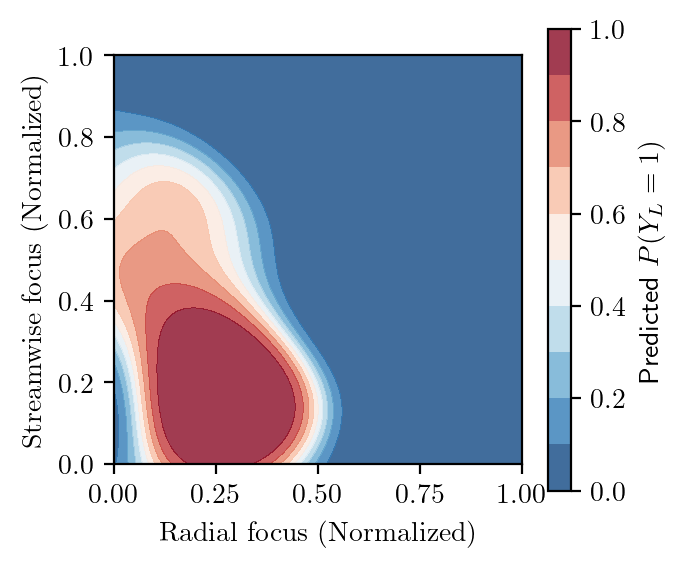

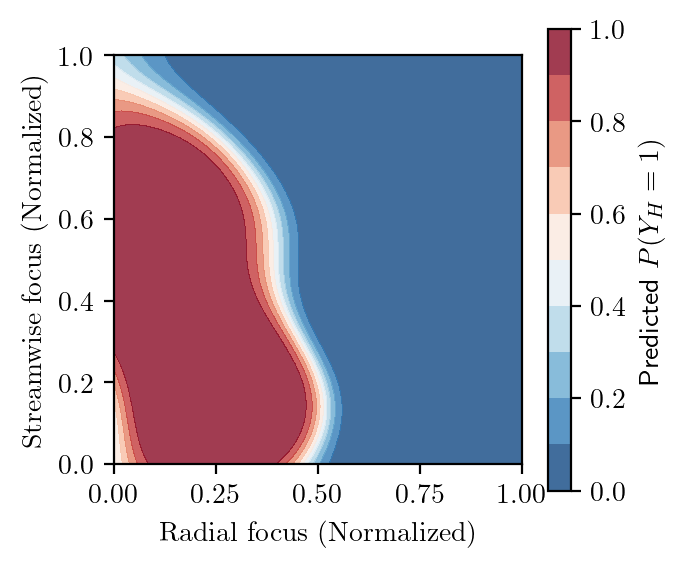

In [42]:
# --- New, Refactored Plotting Functions for Final Predictions ---

def plot_lf_predictions(model, X_lf_train, Y_lf_train, title, grid_res=100):
    """
    Plots the final LF prediction surface with its training data overlaid.
    """
    model.eval()
    xi = np.linspace(0, 1, grid_res)
    yi = np.linspace(0, 1, grid_res)
    xx, yy = np.meshgrid(xi, yi)
    grid_points_np = np.vstack([xx.ravel(), yy.ravel()]).T
    grid_points_torch = torch.tensor(grid_points_np, dtype=torch.float32)

    with torch.no_grad(), gpytorch.settings.fast_pred_var():
        # Get LF predictions
        lf_latent_output = model.lf_model(grid_points_torch)
        predicted_probs_lf_grid = model.lf_likelihood(lf_latent_output).mean

    lf_probs_reshaped = predicted_probs_lf_grid.numpy().reshape(grid_res, grid_res)

    fig, ax = plt.subplots(figsize=(3.5, 3), dpi=200)

    # Low-Fidelity Plot
    contour_lf = ax.contourf(xx, yy, lf_probs_reshaped, levels=np.linspace(0, 1, 11), cmap='RdBu_r', alpha=0.8)
    fig.colorbar(contour_lf, ax=ax, orientation='vertical', label='Predicted $P(Y_L=1)$')

    ax.set_xlabel('$\\textrm{Radial focus (Normalized)}$')
    ax.set_ylabel('$\\textrm{Streamwise focus (Normalized)}$')
    #ax.set_title(title, fontsize=16, pad=15)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal', adjustable='box')
    plt.tight_layout()

    plt.savefig(title + '.pdf')


    
    # ax.scatter(X_lf_train[:, 0], X_lf_train[:, 1], c=Y_lf_train, cmap='viridis',
    #            marker='s', edgecolors='k', s=25, alpha=0.7)



def plot_hf_predictions(model, X_hf_train, Y_hf_train, title, grid_res=100):
    """
    Plots the final HF prediction surface with its training data overlaid.
    """
    model.eval()
    xi = np.linspace(0, 1, grid_res)
    yi = np.linspace(0, 1, grid_res)
    xx, yy = np.meshgrid(xi, yi)
    grid_points_np = np.vstack([xx.ravel(), yy.ravel()]).T
    grid_points_torch = torch.tensor(grid_points_np, dtype=torch.float32)

    with torch.no_grad(), gpytorch.settings.fast_pred_var():
        # Get HF predictions
        predicted_probs_hf_grid = model(grid_points_torch)

    hf_probs_reshaped = predicted_probs_hf_grid.numpy().reshape(grid_res, grid_res)

    fig, ax = plt.subplots(figsize=(3.5, 3), dpi=200)

    # High-Fidelity Plot
    contour_hf = ax.contourf(xx, yy, hf_probs_reshaped, levels=np.linspace(0, 1, 11), cmap='RdBu_r', alpha=0.8)
    fig.colorbar(contour_hf, ax=ax, orientation='vertical', label='Predicted $P(Y_H=1)$')

    ax.set_xlabel('$\\textrm{Radial focus (Normalized)}$')
    ax.set_ylabel('$\\textrm{Streamwise focus (Normalized)}$')
    #ax.set_title(title, fontsize=16, pad=15)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal', adjustable='box')
    plt.tight_layout()

    plt.savefig(title + '.pdf')

    # ax.scatter(X_hf_train[:, 0], X_hf_train[:, 1], c=Y_hf_train, cmap='viridis',
    #            marker='o', edgecolors='k', s=50, alpha=0.9)



# --- Updated Calling Logic for Final Model Plots ---

# Plot final model prediction surfaces
if final_al_model:
    final_al_lf_data, final_al_hf_data = al_lf_history[-1], al_hf_history[-1]
    # Create separate plot for LF
    plot_lf_predictions(final_al_model, final_al_lf_data[0], final_al_lf_data[1],
                        'Final BPMI Model - Low-Fidelity Predictions')
    # Create separate plot for HF
    plot_hf_predictions(final_al_model, final_al_hf_data[0], final_al_hf_data[1],
                        'Final BPMI Model - High-Fidelity Predictions')

if final_random_model:
    final_random_lf_data, final_random_hf_data = random_lf_history[-1], random_hf_history[-1]
    # Create separate plot for LF
    plot_lf_predictions(final_random_model, final_random_lf_data[0], final_random_lf_data[1],
                        'Final Random Model - Low-Fidelity Predictions')
    # Create separate plot for HF
    plot_hf_predictions(final_random_model, final_random_hf_data[0], final_random_hf_data[1],
                        'Final Random Model - High-Fidelity Predictions')

In [43]:
len(X_hf_test)

491